In [30]:
import numpy as np
import matplotlib.pyplot as plt
from time import sleep
from scipy.optimize import curve_fit
%matplotlib inline

In [31]:
path = '/Users/robtk/OneDrive/Desktop/3rd year Labs/Nuvistor Triode/'

In [48]:
# Define I_F for this experiment run
I_F = 85.0

# Load in data.
I_A =          np.load(path+f"anode currents for I_F {I_F} mA.npy")
V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F} mA.npy")
alloutputs =   np.load(path+f"alloutputs for I_F {I_F} mA.npy")
error_I_A =    np.load(path+f"anode currents errors for I_F {I_F} mA.npy")

In [34]:
I = (65.0, 70.0, 75.0, 80.0, 85.0, 90, 95.0, 100.0, 105.0)
for I_F in I:   
    # Define I_F for this experiment run

    # Load in data.
    I_A =          np.load(path+f"anode currents for I_F {I_F} mA.npy")
    V_A_circuit =  np.load(path+f"anode voltages for I_F {I_F} mA.npy")
    alloutputs =   np.load(path+f"alloutputs for I_F {I_F} mA.npy")
    error_I_A =    np.load(path+f"anode currents errors for I_F {I_F} mA.npy")
    print(min(V_A_circuit), max(V_A_circuit), V_A_circuit[2]-V_A_circuit[1], len(V_A_circuit))

-0.5 1.4950000000000019 0.0050000000000000044 400
-1.0 1.4950000000000023 0.0050000000000000044 500
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 1.9950000000000028 0.0050000000000000044 600
-1.0 2.495000000000003 0.0050000000000000044 700


In [49]:
I_A

array([-7.0000e-13, -7.0000e-13, -8.0000e-13, -8.0000e-13, -8.0000e-13,
       -8.0000e-13, -9.0000e-13, -8.0000e-13, -8.0000e-13, -8.0000e-13,
       -9.0000e-13, -9.0000e-13, -8.0000e-13, -8.0000e-13, -9.0000e-13,
       -9.0000e-13, -8.0000e-13, -9.0000e-13, -9.0000e-13, -8.0000e-13,
       -8.0000e-13, -7.0000e-13, -9.0000e-13, -8.0000e-13, -7.0000e-13,
       -7.0000e-13, -8.0000e-13, -8.0000e-13, -7.0000e-13, -7.0000e-13,
       -8.0000e-13, -7.0000e-13, -7.0000e-13, -7.0000e-13, -9.0000e-13,
       -1.6000e-12, -7.0000e-13, -7.0000e-13, -8.0000e-13, -8.0000e-13,
       -7.0000e-13, -7.0000e-13, -8.0000e-13, -7.0000e-13, -7.0000e-13,
       -7.0000e-13, -7.0000e-13, -7.0000e-13, -7.0000e-13, -8.0000e-13,
       -7.0000e-13, -8.0000e-13, -7.0000e-13, -8.0000e-13, -7.0000e-13,
       -7.0000e-13, -8.0000e-13, -8.0000e-13, -8.0000e-13, -7.0000e-13,
       -8.0000e-13, -9.0000e-13, -8.0000e-13, -7.0000e-13, -8.0000e-13,
       -8.0000e-13, -8.0000e-13, -7.0000e-13, -8.0000e-13, -8.00

In [50]:
# Create the error array for the anode currents
I_A_error = []

i = 0
while i <= len(I_A):
    if I_A[i] <= 2e-12:
        
    elif I_A[i] <= 2e-11:
        
    elif I_A[i] <= 2e-10:
        
    elif I_A[i] <= 2e-9:
        
    elif I_A[i] <= 2e-8:
        
    elif I_A[i] <= 2e-7:
        
    else:
        

IndentationError: expected an indented block (<ipython-input-50-ce83aae33905>, line 8)

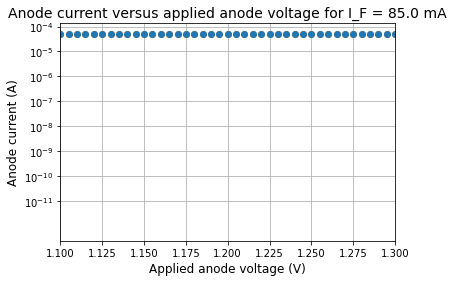

In [51]:
# plot of experimental anode current versus applied voltage with errors.
plt.errorbar(V_A_circuit, (-I_A), error_I_A,
             fmt = 'o')

plt.plot(V_A_circuit, (-I_A), "o")
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
plt.ylabel("Anode current (A)", fontsize = 12)
plt.title(f"Anode current versus applied anode voltage for I_F = {I_F} mA", fontsize = 14);

# Zoom in to find the exact saturated anode current
plt.xlim(1.1, 1.3)

plt.yscale("log")
plt.yticks([1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]);
plt.grid(True)
plt.savefig("raw i-v", dpi = 100, 
            bbox_inches = "tight");

#### Calculate electron temperature

During the retarding-potential range, Equation 1 is valid which states that the anode current per unit anode length equals the cathode current per unit cathode length

Therefore $\frac{I_L}{I_{LS}} = \frac{I_A}{I_{AS}}$

In [52]:
# Defining equation of line of best fit 
def fitfunc(x, m, c):
    return x*m+c

In [53]:
plt.plot(V_A_circuit,  np.log10(-I_A/-I_AS))

NameError: name 'I_AS' is not defined

In [54]:
# From visual inspection of the above graph, the saturation current is found.
# Here, the V_AS is found in the V_A_circuit array.
print(V_A_circuit[410])
I_A[410]

1.0500000000000016


-5.0079999999999995e-05

-5.0079999999999995e-05
[ 7.32464519 -6.83357481]
[[ 3.70517131e-05 -1.84332272e-05]
 [-1.84332272e-05  9.94236399e-06]]


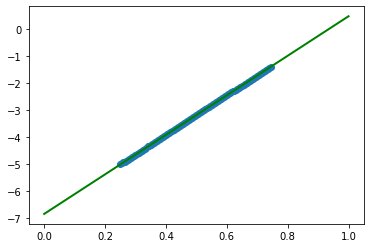

In [58]:
# The saturated anode current is I_AS which is gotten by inspection of the graph.
I_AS = I_A[410]
print(I_AS)
error_I_AS = error_I_A[410]

plt.plot(V_A_circuit[250:350], np.log10(-I_A/-I_AS)[250:350], "o")

pars1, cov1 = curve_fit(fitfunc, V_A_circuit[250:350],  np.log10(-I_A/-I_AS)[250:350])

plt.plot(np.linspace(1,0,3), fitfunc(np.linspace(1,0,3), *pars1), 'g-'
         , linewidth = '2', label = "Second four data points' line of best fit")
print(pars1)
print(cov1)



In [60]:
T = 5040/pars1[0]
error_on_slope = np.sqrt(cov1[0,0])

error_T = np.sqrt((-5040/pars1[0]**2)**2 * error_on_slope**2)
print("Temperature is",T,"+ or -",error_T)

Temperature is 688.0879372223798 + or - 0.5718228403524885


Plot Schottky curve for this electron temperature

In [61]:
# eta_A values are theoretically derived from the Schottky equation [Luke. K].
eta_A = np.array([0, -0.2, -0.4, -0.6, -0.8, -1, -2, -3, -4, -5])

V_R = 1.380649e-23 * T * eta_A / 1.602176565e-19
V_R

array([ 0.        , -0.01185897, -0.02371793, -0.0355769 , -0.04743587,
       -0.05929483, -0.11858967, -0.1778845 , -0.23717933, -0.29647417])

In [62]:
# log10(I_L/I_LS) values are theoretically derived from the Schottky equation and the dimensions of the 6CW4 [Luke. K].
logI_L_over_I_LS = np.array([0, -3.371e-2, -8.825e-2, -1.521e-1, -2.216e-1, -2.949e-1, -6.919e-1, -1.111, -1.539, -1.970])

# Find the theoretical log10(anode current) for creating the Schottky curve [equation 14 from Luke, K.].
logI_A_Schottky = logI_L_over_I_LS + np.log10(-I_AS)

I_A_Schottky = 10**(logI_L_over_I_LS*-I_AS)

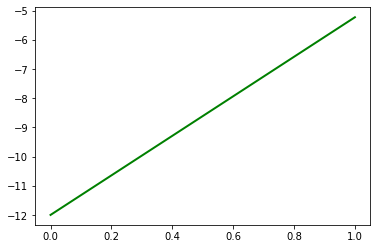

In [63]:
pars2, cov2 = curve_fit(fitfunc, V_R, logI_A_Schottky)
plt.plot(np.linspace(0,-1,3)+1, fitfunc(np.linspace(0,-1,3), *pars2)-1+1.46e-4, 'g-'
         , linewidth = '2', label = "Second four data points' line of best fit")


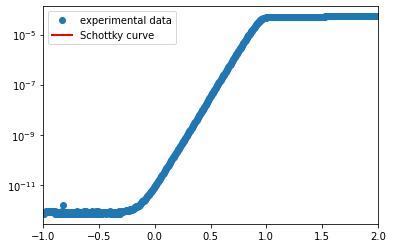

In [64]:
plt.plot(V_A_circuit, -I_A, "o", label = "experimental data")

# pars2 is the slope of the linear line of best fit for the Schottky curve.
pars2, cov2 = curve_fit(fitfunc, V_R, logI_A_Schottky)
plt.plot(np.linspace(0,-1,3)+1, fitfunc(np.linspace(0,-1,3), *pars2+4), 'r'
         , linewidth = '2', label = "Schottky curve")


# The horizontal line at V_R = 0 is plotted to complete the Schottky curve.
plt.plot(np.linspace(0,2,3)+1, np.zeros(3) + fitfunc(0, *pars2+4), "r", linewidth = "2");

plt.yscale("log")
plt.legend()
plt.xlim(-1, 2);

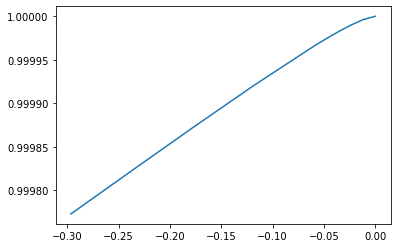

In [65]:
plt.plot(V_R, I_A_Schottky)
#plt.plot(np.arange(0,20,1), np.zeros(20) + I_AS)

Define constants needed to calculate the effective work functions

In [63]:
V_A_circuit[100]
np.where(np.isclose(V_A_circuit, 0))

(array([200], dtype=int64),)

In [64]:
I_S = 1.5 * -I_AS
error_I_S = 1.5 * error_I_AS

# Define I_AO, the anode current when V_A_circuit = 0
index = np.where(np.isclose(V_A_circuit, 0))
I_AO = -I_A[index]
error_I_AO = error_I_A[index]

# Define the effective cathode area
A_CE = 0.134
error_A_CE = 0.0005

# Define the ratio between anode radius and cathode radius R_A
R_A = 1.60
error_R_A = 0.022

Determine effective cathode work function and its error

In [65]:
cathode_phi = 1.984e-4 * T * (2.079 + 2 * np.log10(T) - np.log10( I_S /A_CE))
cathode_phi

2.532042289451761

In [66]:
derivative_cathode_phi_dT = 1.984e-4*(2.079 + 2 * np.log10(T) - np.log10(I_S /A_CE)) + 1.984e-4 * T * 2/( T * np.log(10) )

derivative_cathode_phi_dI_S = 1.984e-4 * T * 1/( I_S * np.log(10) )

derivative_cathode_phi_dA_CE = 1.984e-4 * T * -1/( A_CE * np.log(10) )

error_cathode_phi = np.sqrt( derivative_cathode_phi_dT**2 * error_T**2 + 
                             derivative_cathode_phi_dI_S**2 * error_I_S**2 +
                             derivative_cathode_phi_dA_CE**2 * error_A_CE**2 )

error_cathode_phi

0.037663712393203964

Determine effective anode work function and its error

In [67]:
anode_phi = 1.984e-4 * T * (2.079 + np.log10(R_A) + 2 * np.log10(T) - np.log10(I_AO / A_CE))
anode_phi

array([3.18424722])

In [22]:
derivative_anode_phi_dT = 1.984e-4*(2.079 + np.log10(R_A)+ 2*np.log10(T) - np.log10(I_AO / A_CE)) + 1.984e-4*T*2/(T*np.log(10))

derivative_anode_phi_dR_A = 1.984e-4 * T * 1/(R_A * np.log(10))

derivative_anode_phi_dI_AO = 1.984e-4 * T * -1/(I_AO * np.log(10))

derivative_anode_phi_dA_CE = 1.984e-4 * T * 1/(A_CE * np.log(10))

error_anode_phi = np.sqrt( derivative_anode_phi_dT**2 * error_T**2 + 
                           derivative_anode_phi_dR_A**2 * error_R_A**2 +
                           derivative_anode_phi_dI_AO**2 * error_I_AO**2 +
                           derivative_anode_phi_dA_CE**2 * error_A_CE**2 )

error_anode_phi

array([0.0134595])

Determine contact potential difference method 1; by anode_phi - cathode_phi

In [23]:
contact_potential_1 = anode_phi - cathode_phi
contact_potential_1

array([0.56725464])

Determine contact potential difference method 2; V_A_circuit point corresponding to V_R = 0 on the Schottky plot

In [24]:
contact_potential_2 = 

SyntaxError: invalid syntax (<ipython-input-24-e67e55fa8c92>, line 1)

#### Note the filament current for each experiment run

In [ ]:
I_F = []

#### Find the experimental saturated anode current for each filament current

In [ ]:
path = "C:/Users/robtk/OneDrive/Desktop/3rd year Labs/Nuvistor Triode/"

In [ ]:
# Load in data
I_F = 
I_A =          np.load(path+"anode currents for I_F = %f mA.npy" %I_F)
V_A_circuit =  np.load(path+"anode voltages for I_F = %f.npy" %I_F)
alloutputs =   np.load(path+"alloutputs for I_F = %f.npy" %I_F)
error_I_A =    np.load(path+"anode currents errors for I_F = %f.npy" %I_F)

In [ ]:
plt.plot(V_A_circuit, (-I_A), "o")
plt.xlabel("Applied anode voltage (V)", fontsize = 12)
plt.ylabel("Anode current (A)", fontsize = 12)
plt.title("I-V curve of anode current versus applied anode voltage in the nuvistor triode", fontsize = 12);
#plt.xlim(0.7, 1.2)

#### Create a function that does the data analysis for each I_F value 

In [ ]:
# Defining equation of line of best fit 
def fitfunc(x, m, c):
    return x*m+c

In [ ]:
I_F =  []
I_AS = []

T = []
error_T = []
pars = []
cov = []

plt.figure(figsize = (15,30))

i = 0
while i < len(I_F)
    
    I_A =         np.load(path+"anode currents for I_F = %f mA.npy" %I_F[i])
    V_A_circuit = np.load(path+"anode voltages for I_F = %f.npy" %I_F[i])
    alloutputs =  np.load(path+"alloutputs for I_F = %f.npy" %I_F[i])
    error_I_A =   np.load(path+"anode currents errors for I_F = %f.npy" %I_F[i])
    
    #Calculate electron temperature
    
    # The saturated anode current is I_AS which is gotten by inspection of the graph.
    I_AS = 1.4653e-04
    error_I_AS = error_I_A[np.where(I_A == I_AS)]
    
    pars[i], cov[i] = curve_fit(fitfunc, V_A_circuit[120:180],  np.log10(-I_A/I_AS)[120:180])
    

    print(pars1)
    print(cov1)

    
    T[i] = 5040/pars1[0]
    error_on_slope = np.sqrt(cov1[0,0])

    error_T[i] = np.sqrt((-5040/pars1[0]**2)**2 * error_on_slope**2)
    print("Temperature is",T[i],"+ or -",T_error[i], "for I_F = %f" %I_F[i])
    
    
    
    i += 1

In [ ]:
for el in [1,2,3,4,5,6,7,8,9]:
    plt.plot(1, el)
    print("Hi")